In [9]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt



In [10]:
cafe = pd.read_csv("Cafe_Sales.csv")
cafe

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4,3,12,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,27-04-2023
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,11-06-2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2,4,NaN,UNKNOWN,30-08-2023
9996,TXN_9659401,NaN,3,NaN,3,Digital Wallet,NaN,02-06-2023
9997,TXN_5255387,Coffee,4,2,8,Digital Wallet,NaN,02-03-2023
9998,TXN_7695629,Cookie,3,NaN,3,Digital Wallet,NaN,02-12-2023


In [11]:
cafe = cafe.drop(columns=["Transaction ID", "Transaction Date"])

In [12]:
cafe

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
0,Coffee,2,2,4,Credit Card,Takeaway
1,Cake,4,3,12,Cash,In-store
2,Cookie,4,1,ERROR,Credit Card,In-store
3,Salad,2,5,10,UNKNOWN,UNKNOWN
4,Coffee,2,2,4,Digital Wallet,In-store
...,...,...,...,...,...,...
9995,Coffee,2,2,4,NaN,UNKNOWN
9996,NaN,3,NaN,3,Digital Wallet,NaN
9997,Coffee,4,2,8,Digital Wallet,NaN
9998,Cookie,3,NaN,3,Digital Wallet,NaN


In [13]:
cafe.shape

(10000, 6)

In [14]:
cafe.describe()

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
count,9666,9858,9816,9824,7421,6733
unique,10,7,8,19,5,4
top,Juice,5,3,6,Digital Wallet,Takeaway
freq,1171,2013,2429,979,2291,3022


In [15]:
cafe.mean(numeric_only=True)

Series([], dtype: float64)

In [16]:
cafe.median(numeric_only=True)

Series([], dtype: float64)

In [17]:
cafe.mode(numeric_only=True)

""


In [18]:
cafe.std(numeric_only = True)

Series([], dtype: float64)

In [19]:
cafe.var(numeric_only = True)

Series([], dtype: float64)

In [20]:
cafe.isnull().any()

Item              True
Quantity          True
Price Per Unit    True
Total Spent       True
Payment Method    True
Location          True
dtype: bool

In [21]:
cafe.isnull().sum()

Item               334
Quantity           142
Price Per Unit     184
Total Spent        176
Payment Method    2579
Location          3267
dtype: int64

In [22]:
le = LabelEncoder()

cols = ['Item', 'Payment Method', 'Location']

for col in cols:
    cafe[col]=le.fit_transform(cafe[col])

In [23]:
cafe

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
0,1,2,2,4,1,2
1,0,4,3,12,0,1
2,2,4,1,ERROR,1,1
3,5,2,5,10,4,3
4,1,2,2,4,2,1
...,...,...,...,...,...,...
9995,1,2,2,4,5,3
9996,10,3,NaN,3,2,4
9997,1,4,2,8,2,4
9998,2,3,NaN,3,2,4


In [24]:
cafe["Item"] = cafe["Item"].fillna(cafe.Item.mode()[0])

In [25]:
cafe["Quantity"] = pd.to_numeric(cafe["Quantity"], errors='coerce')
cafe["Quantity"] = cafe["Quantity"].fillna(cafe["Quantity"].median())

In [26]:
cafe["Price Per Unit"] = pd.to_numeric(cafe["Price Per Unit"], errors='coerce')
cafe["Price Per Unit"] = cafe["Price Per Unit"].fillna(cafe["Price Per Unit"].median())

In [27]:
cafe["Total Spent"] = pd.to_numeric(cafe["Total Spent"], errors='coerce')
cafe["Total Spent"] = cafe["Total Spent"].fillna(cafe["Total Spent"].median())

In [28]:
cafe["Payment Method"] = cafe["Payment Method"].fillna(cafe['Payment Method'].mode()[0])

In [29]:
cafe["Location"] = cafe["Location"].fillna(cafe.Location.mode()[0])

In [30]:
cafe.isnull().sum()

Item              0
Quantity          0
Price Per Unit    0
Total Spent       0
Payment Method    0
Location          0
dtype: int64

In [31]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler_cafe = scaler.fit_transform(cafe)
cafe = pd.DataFrame(scaler_cafe, columns = cafe.columns)
cafe

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
0,0.1,0.25,0.25,0.125000,0.2,0.50
1,0.0,0.75,0.50,0.458333,0.0,0.25
2,0.2,0.75,0.00,0.291667,0.2,0.25
3,0.5,0.25,1.00,0.375000,0.8,0.75
4,0.1,0.25,0.25,0.125000,0.4,0.25
...,...,...,...,...,...,...
9995,0.1,0.25,0.25,0.125000,1.0,0.75
9996,1.0,0.50,0.50,0.083333,0.4,1.00
9997,0.1,0.75,0.25,0.291667,0.4,1.00
9998,0.2,0.50,0.50,0.083333,0.4,1.00


In [32]:
cafe.mode(numeric_only=True)


,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
0,0.4,0.5,0.5,0.291667,1.0,1.0


In [33]:
cafe.median(numeric_only=True)

Item              0.500000
Quantity          0.500000
Price Per Unit    0.500000
Total Spent       0.291667
Payment Method    0.400000
Location          0.500000
dtype: float64

In [34]:
cafe.mean(numeric_only=True)

Item              0.442460
Quantity          0.506775
Price Per Unit    0.488162
Total Spent       0.328248
Payment Method    0.436800
Location          0.578500
dtype: float64

In [35]:
cafe

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
0,0.1,0.25,0.25,0.125000,0.2,0.50
1,0.0,0.75,0.50,0.458333,0.0,0.25
2,0.2,0.75,0.00,0.291667,0.2,0.25
3,0.5,0.25,1.00,0.375000,0.8,0.75
4,0.1,0.25,0.25,0.125000,0.4,0.25
...,...,...,...,...,...,...
9995,0.1,0.25,0.25,0.125000,1.0,0.75
9996,1.0,0.50,0.50,0.083333,0.4,1.00
9997,0.1,0.75,0.25,0.291667,0.4,1.00
9998,0.2,0.50,0.50,0.083333,0.4,1.00


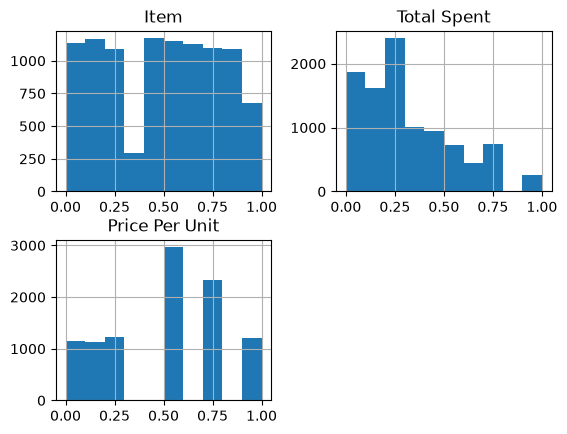

<Figure size 640x480 with 0 Axes>

In [36]:
import matplotlib.pyplot as plt
cafe[['Item','Total Spent','Price Per Unit']].hist()
plt.show()
plt.tight_layout()

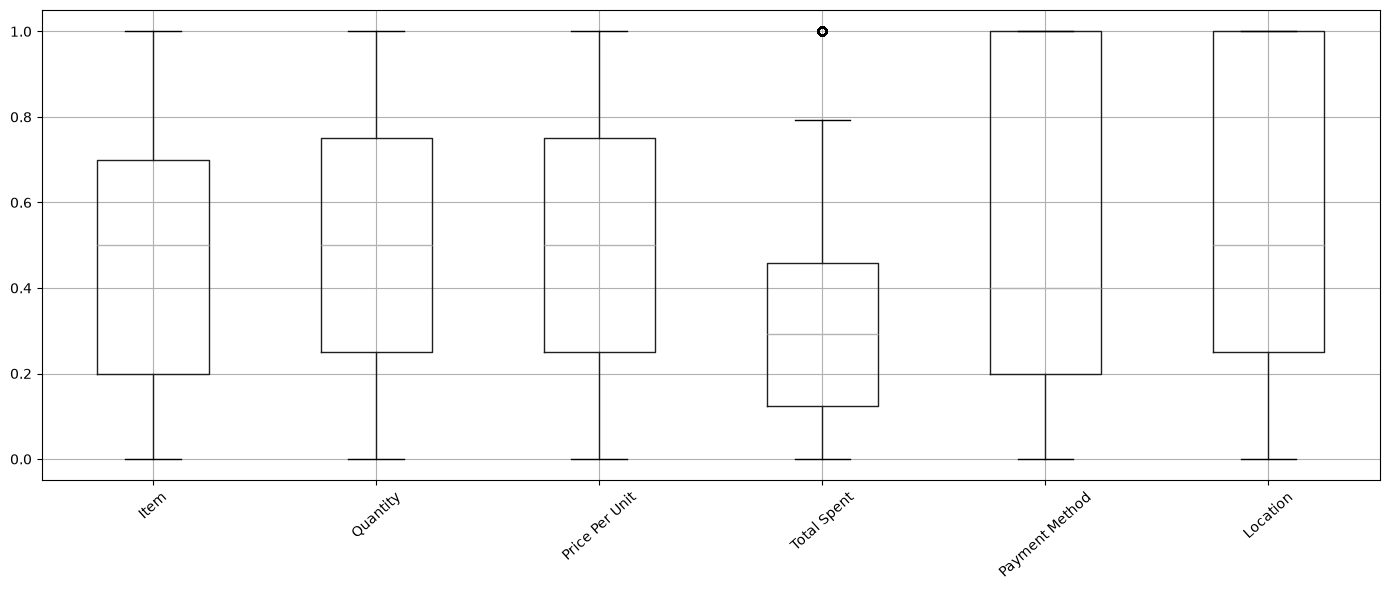

In [37]:
cafe.boxplot(figsize=(14, 6), rot=42)
plt.tight_layout()

In [38]:
from sklearn.model_selection import train_test_split

x = cafe

x_train,x_test = train_test_split(x , train_size=0.8, random_state=42)

x_train

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location
9254,0.2,0.00,0.00,0.000000,0.0,0.25
1561,0.4,0.25,0.50,0.208333,0.2,0.00
1670,0.0,0.25,0.50,0.208333,0.0,0.25
6087,1.0,0.50,0.75,0.458333,0.8,0.00
6669,0.7,0.50,0.75,0.458333,0.0,1.00
...,...,...,...,...,...,...
5734,0.0,0.75,0.50,0.458333,0.2,0.25
5191,0.1,0.75,0.25,0.291667,0.2,1.00
5390,0.2,0.00,0.00,0.000000,0.0,1.00
860,0.7,0.25,0.75,0.291667,1.0,1.00


In [ ]:
x_test